#Analiza Eksploracyjna danych 

Zbiór danych któremu teraz się przyjrzymy donosi się do wielkości pozwalających określić atrakcyjnośc poszczególnych obszarów w krajach bałkańskich, dane te podzielone są na kraje oraz przydzie4lone na podstawie standardu NUTS regionów.

#Wczytanie potrzebnych bibliotek

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#Wczytanie danych

In [19]:


df = pd.read_excel('baza_balkany.xlsx')
pd.set_option('display.float_format', lambda x: '%.2f' % x)


Przyjrzyjmy się jakie dokładnie mamy dane w zbiorze

In [21]:
df.describe()


,Year,Noclegi_Ogolem,Noclegi_Zagraniczne,Liczba_Obiektow,Ruch_Lotniczy,Poziom_Cen_NUTS0,Wody_Doskonała_Jakość_NUTS0
count,282.00,282.00,282.00,273.00,196.00,282.00,252.00
mean,2021.10,4279636.47,3035598.93,4526.03,3665.28,66.15,747.91
std,1.98,6242454.53,5980917.51,16545.35,5369.77,14.98,742.40
min,2018.00,140050.00,18207.00,112.00,0.04,44.60,21.00
25%,2019.00,1035128.00,239813.75,621.00,463.14,52.10,49.00
50%,2021.00,2014405.00,766030.50,1148.00,1447.32,59.30,113.00
75%,2023.00,4203601.00,2064928.50,2395.00,4329.07,83.90,1631.00
max,2024.00,32447938.00,30600629.00,115285.00,31599.50,91.00,1728.00


In [22]:
df.dtypes




geo                                str
Year                             int64
Noclegi_Ogolem                   int64
Noclegi_Zagraniczne              int64
Liczba_Obiektow                float64
Ruch_Lotniczy                  float64
NUTS0                              str
Poziom_Cen_NUTS0               float64
Wody_Doskonała_Jakość_NUTS0    float64
dtype: object

Sprawdzmy czy nasze dane nie zawierają jakiś braków

In [23]:
df.isnull().sum()


geo                             0
Year                            0
Noclegi_Ogolem                  0
Noclegi_Zagraniczne             0
Liczba_Obiektow                 9
Ruch_Lotniczy                  86
NUTS0                           0
Poziom_Cen_NUTS0                0
Wody_Doskonała_Jakość_NUTS0    30
dtype: int64

Braki w danych odnośnie ruchu lotniczego, oraz jakości wód dość łatwo wytłumaczyć nieobecnością latnisk i terenów wodnych w tych obszarach, zastąpimy wartości Null zwykłym zerem.

In [24]:
df['Ruch_Lotniczy']= df['Ruch_Lotniczy'].fillna(0 , inplace=True)
df['Wody_Doskonała_Jakość_NUTS0']= df['Wody_Doskonała_Jakość_NUTS0'].fillna(0 , inplace=True)


C:\Users\filip\AppData\Local\Temp\ipykernel_4876\1680223108.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Ruch_Lotniczy']= df['Ruch_Lotniczy'].fillna(0 , inplace=True)
C:\Users\filip\AppData\Local\Temp\ipykernel_4876\1680223108.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through cha

Zbadajmy teraz unikalność danych 

In [13]:
df.nunique() / len(df) * 100



geo                            15.25
Year                            2.48
Noclegi_Ogolem                100.00
Noclegi_Zagraniczne           100.00
Liczba_Obiektow                91.84
Ruch_Lotniczy                  69.86
NUTS0                           3.19
Poziom_Cen_NUTS0               18.44
Wody_Doskonała_Jakość_NUTS0     4.96
dtype: float64

Przyjrzyjmy się teraz skorelowaniu danych, naturalnym pytaniem które sobię stawiamy jest czy obszary popularne w danym kraju, bedą pokrywać się wraz z obszarami popularnymi wśród turystów? 

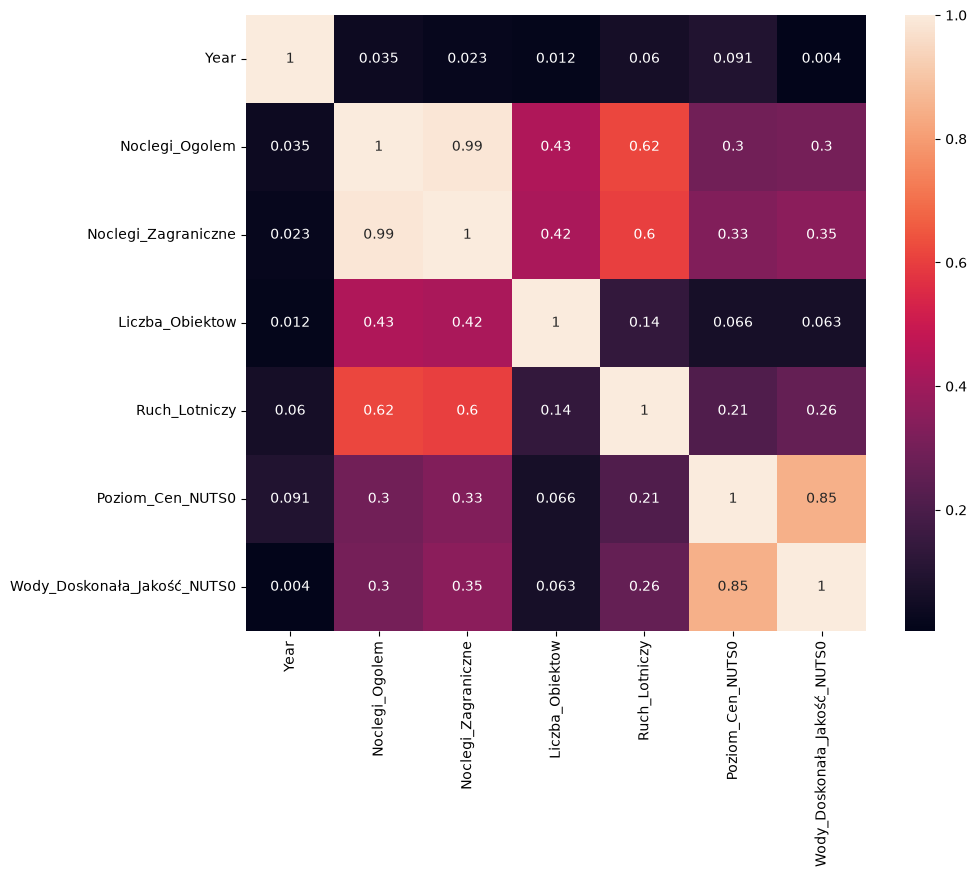

In [17]:
plt.rcParams['figure.figsize'] = (10, 8)
sns.heatmap(df.corr(numeric_only=True), annot=True)    
plt.show()

Jak widzimy nasza teza się potwierdza, my jednak w póżniejszym badaniu posłużymy się dwoma nowymi wskaźnikami dotyczącymi tych danych, procentową wartością zagranicznych turystów, oraz ilością gości w ogóle.

In [ ]:
df.groupby('geo')